# 🎓 EdTech Lead Scoring: EDA, Cleaning & Model Experimentation
**Objective:** Predict lead conversion (`is_converted`) in a 14-day post-reachout window without data leakage.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.feature_selection import mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, precision_recall_curve, auc
import xgboost as xgb
import pickle

pd.set_option('display.max_columns', None)
plt.style.use('seaborn-v0_8-whitegrid')
%matplotlib inline

## 1. Raw Dataset Observation

In [ ]:
df_raw = pd.read_csv('data/edtech_advanced_dataset.csv')
print(f"Raw dataset shape: {df_raw.shape}")
df_raw.head()

Raw dataset shape: (2000, 19)


,student_id,user_country_code,discovery_channel,primary_interest,days_signup_vs_reachout,replied_to_followup_email,sent_second_message,free_courses_enrolled_count,free_semantic_model_completed,platform_logins_count_14d,total_video_minutes_watched_14d,is_converted,enrollment_type,months_since_enrollment,sessions_30min_booked,projects_submitted_count,reported_ai_tool_usage,passed_ai_comprehension_check,is_stalled_or_abandoned
0,STU_202600,GR,YouTube,Data Analytics,7.0,0,0,1,0,1,3.8,0,NaN,0,0,0,0,0,NaN
1,STU_202601,GR,LinkedIn,Data Analytics,-1.8,0,0,1,1,4,65.7,0,NaN,0,0,0,0,0,NaN
2,STU_202602,US,YouTube,Power BI,-4.7,0,0,0,0,2,46.8,0,NaN,0,0,0,0,0,NaN
3,STU_202603,GR,linkedin,Data Analytics,1.9,0,0,1,0,4,98.4,0,NaN,0,0,0,0,0,NaN
4,STU_202604,GR,LinkedIn,NaN,-10.6,0,0,2,0,5,0.3,0,NaN,0,0,0,0,0,NaN


In [3]:
print("=== Column Info & Missing Values ===")
df_raw.info()

=== Column Info & Missing Values ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 19 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   student_id                       2000 non-null   object 
 1   user_country_code                2000 non-null   object 
 2   discovery_channel                1938 non-null   object 
 3   primary_interest                 1876 non-null   object 
 4   days_signup_vs_reachout          2000 non-null   float64
 5   replied_to_followup_email        2000 non-null   int64  
 6   sent_second_message              2000 non-null   int64  
 7   free_courses_enrolled_count      2000 non-null   int64  
 8   free_semantic_model_completed    2000 non-null   int64  
 9   platform_logins_count_14d        2000 non-null   int64  
 10  total_video_minutes_watched_14d  2000 non-null   float64
 11  is_converted                     2000 non-nul

In [4]:
print("=== Target Distribution (is_converted) ===")
conv_dist = df_raw['is_converted'].value_counts(normalize=True) * 100
print(f"Non-converted (0): {conv_dist[0]:.2f}%")
print(f"Converted     (1): {conv_dist[1]:.2f}%")

=== Target Distribution (is_converted) ===
Non-converted (0): 73.25%
Converted     (1): 26.75%


## 2. Anti-Leakage Feature Isolation & Cleaning
Απομονώνουμε **μόνο** τα pre-conversion χαρακτηριστικά του Midterm Project και αφαιρούμε τις post-purchase στήλες (`enrollment_type`, `is_stalled_or_abandoned` κλπ).

In [5]:
midterm_columns = [
    'student_id',
    'user_country_code',
    'discovery_channel',
    'primary_interest',
    'days_signup_vs_reachout',
    'replied_to_followup_email',
    'sent_second_message',
    'free_courses_enrolled_count',
    'free_semantic_model_completed',
    'platform_logins_count_14d',
    'total_video_minutes_watched_14d',
    'is_converted'
]
df_midterm = df_raw[midterm_columns].copy()

# Ενοποίηση τιμών στο discovery_channel
channel_unification_map = {'linkedin': 'LinkedIn', 'LI': 'LinkedIn', 'yt': 'YouTube'}
df_midterm['discovery_channel'] = df_midterm['discovery_channel'].replace(channel_unification_map).fillna('Unknown')
df_midterm['primary_interest'] = df_midterm['primary_interest'].fillna('Unknown')

print("Missing values after cleaning:")
print(df_midterm.isnull().sum())

Missing values after cleaning:
student_id                         0
user_country_code                  0
discovery_channel                  0
primary_interest                   0
days_signup_vs_reachout            0
replied_to_followup_email          0
sent_second_message                0
free_courses_enrolled_count        0
free_semantic_model_completed      0
platform_logins_count_14d          0
total_video_minutes_watched_14d    0
is_converted                       0
dtype: int64


## 3. Behavioral Insights & Hypothesis Testing

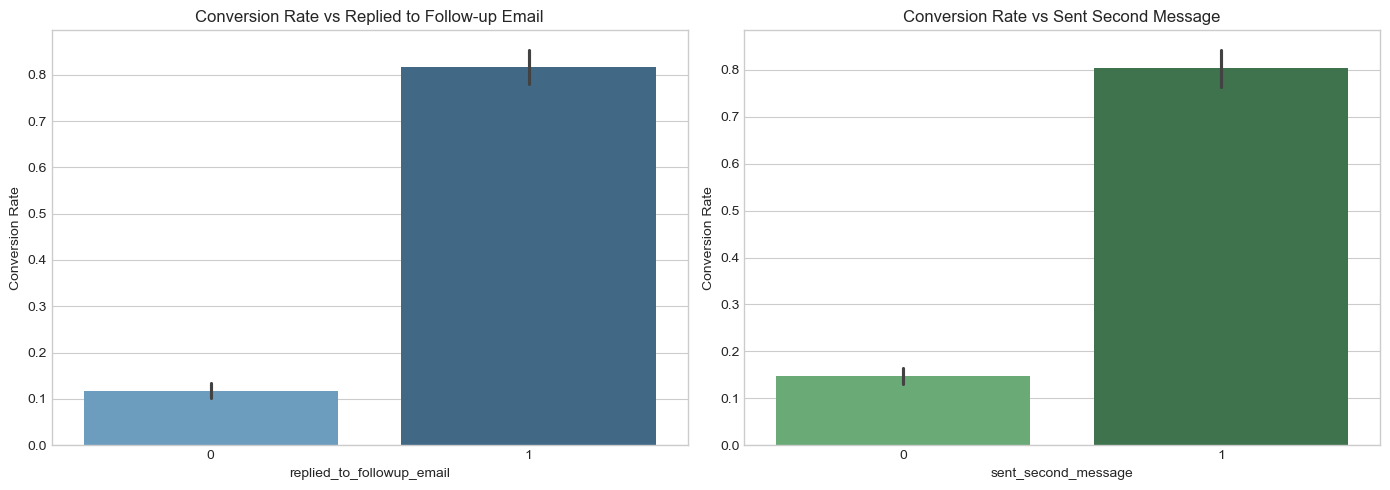

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=df_midterm, x='replied_to_followup_email', y='is_converted', hue='replied_to_followup_email', ax=axes[0], palette='Blues_d', legend=False)
axes[0].set_title('Conversion Rate vs Replied to Follow-up Email')
axes[0].set_ylabel('Conversion Rate')

sns.barplot(data=df_midterm, x='sent_second_message', y='is_converted', hue='sent_second_message', ax=axes[1], palette='Greens_d', legend=False)
axes[1].set_title('Conversion Rate vs Sent Second Message')
axes[1].set_ylabel('Conversion Rate')

plt.tight_layout()
plt.show()

## 4. Feature Selection via Mutual Information
Ελέγχουμε την πληροφοριακή αξία. Παρατηρούμε ότι το `user_country_code` έχει μηδενική συσχέτιση με το conversion και επιβεβαιώνεται ως **noise feature** που πρέπει να αφαιρεθεί.

In [7]:
X_temp = df_midterm.drop(columns=['student_id', 'is_converted']).to_dict(orient='records')
dv_temp = DictVectorizer(sparse=False)
X_temp_encoded = dv_temp.fit_transform(X_temp)
y_temp = df_midterm['is_converted'].values

mi_scores = mutual_info_classif(X_temp_encoded, y_temp, random_state=42)
mi_series = pd.Series(mi_scores, index=dv_temp.get_feature_names_out()).sort_values(ascending=False)

print("=== Mutual Information Scores ===")
print(mi_series)

=== Mutual Information Scores ===
replied_to_followup_email                 0.194173
sent_second_message                       0.150115
discovery_channel=Unknown                 0.011268
discovery_channel=Newsletter              0.008676
user_country_code=US                      0.007030
primary_interest=Unknown                  0.005975
user_country_code=DE                      0.005661
primary_interest=Data Analytics           0.003417
discovery_channel=Referral                0.003245
days_signup_vs_reachout                   0.000000
discovery_channel=LinkedIn                0.000000
discovery_channel=Google                  0.000000
discovery_channel=YouTube                 0.000000
free_courses_enrolled_count               0.000000
primary_interest=Power BI                 0.000000
primary_interest=Analytics Engineering    0.000000
free_semantic_model_completed             0.000000
platform_logins_count_14d                 0.000000
user_country_code=CY                      0.0000

## 5. Exporting Cleaned Dataset
Αποθηκεύουμε το καθαρισμένο dataset `edtech_midterm_clean.csv`.

In [ ]:
# Αποθήκευση του καθαρισμένου dataset για αυτόνομη χρήση στο train.py
df_midterm.to_csv('data/edtech_midterm_clean.csv', index=False)
print("Saved cleaned dataset as 'edtech_midterm_clean.csv' successfully.")

Saved cleaned dataset as 'edtech_midterm_clean.csv' successfully.


## 6. Model Training & Experimentation Matrix (EXP-01 to EXP-05)

In [9]:
final_features = [
    'discovery_channel',
    'primary_interest',
    'days_signup_vs_reachout',
    'replied_to_followup_email',
    'sent_second_message',
    'free_courses_enrolled_count',
    'free_semantic_model_completed',
    'platform_logins_count_14d',
    'total_video_minutes_watched_14d'
]

df_full_train, df_test = train_test_split(
    df_midterm, test_size=0.20, random_state=42, stratify=df_midterm['is_converted']
)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=42, stratify=df_full_train['is_converted']
)

y_train = df_train['is_converted'].values
y_val = df_val['is_converted'].values
y_test = df_test['is_converted'].values

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(df_train[final_features].to_dict(orient='records'))
X_val = dv.transform(df_val[final_features].to_dict(orient='records'))
X_test = dv.transform(df_test[final_features].to_dict(orient='records'))

def calc_pr_auc(y_true, y_pred_prob):
    p, r, _ = precision_recall_curve(y_true, y_pred_prob)
    return auc(r, p)

results = []

# EXP-01: Logistic Regression Full (with user_country_code)
dv_full = DictVectorizer(sparse=False)
X_tr_f = dv_full.fit_transform(df_train.drop(columns=['student_id', 'is_converted']).to_dict(orient='records'))
X_va_f = dv_full.transform(df_val.drop(columns=['student_id', 'is_converted']).to_dict(orient='records'))
lr_full = LogisticRegression(max_iter=1000, random_state=42)
lr_full.fit(X_tr_f, y_train)
p_exp1 = lr_full.predict_proba(X_va_f)[:, 1]
results.append({'Experiment': 'EXP-01', 'Model': 'Logistic Regression (Full)', 'Val ROC-AUC': round(roc_auc_score(y_val, p_exp1), 4), 'Val PR-AUC': round(calc_pr_auc(y_val, p_exp1), 4)})

# EXP-02: Logistic Regression Filtered (no country noise)
lr_filt = LogisticRegression(max_iter=1000, random_state=42)
lr_filt.fit(X_train, y_train)
p_exp2 = lr_filt.predict_proba(X_val)[:, 1]
results.append({'Experiment': 'EXP-02', 'Model': 'Logistic Regression (Filtered)', 'Val ROC-AUC': round(roc_auc_score(y_val, p_exp2), 4), 'Val PR-AUC': round(calc_pr_auc(y_val, p_exp2), 4)})

# EXP-03: Decision Tree
dt_best = DecisionTreeClassifier(max_depth=4, random_state=42)
dt_best.fit(X_train, y_train)
p_exp3 = dt_best.predict_proba(X_val)[:, 1]
results.append({'Experiment': 'EXP-03', 'Model': 'Decision Tree (depth=4)', 'Val ROC-AUC': round(roc_auc_score(y_val, p_exp3), 4), 'Val PR-AUC': round(calc_pr_auc(y_val, p_exp3), 4)})

# EXP-04: Random Forest
rf = RandomForestClassifier(n_estimators=100, max_depth=4, random_state=42)
rf.fit(X_train, y_train)
p_exp4 = rf.predict_proba(X_val)[:, 1]
results.append({'Experiment': 'EXP-04', 'Model': 'Random Forest (n=100, d=4)', 'Val ROC-AUC': round(roc_auc_score(y_val, p_exp4), 4), 'Val PR-AUC': round(calc_pr_auc(y_val, p_exp4), 4)})

# EXP-05: XGBoost
feature_names = list(dv.get_feature_names_out())
dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=feature_names)
dval = xgb.DMatrix(X_val, label=y_val, feature_names=feature_names)
xgb_params = {'eta': 0.1, 'max_depth': 4, 'objective': 'binary:logistic', 'eval_metric': 'auc', 'seed': 42}
model_xgb = xgb.train(xgb_params, dtrain, num_boost_round=100)
p_exp5 = model_xgb.predict(dval)
results.append({'Experiment': 'EXP-05', 'Model': 'XGBoost (eta=0.1, d=4)', 'Val ROC-AUC': round(roc_auc_score(y_val, p_exp5), 4), 'Val PR-AUC': round(calc_pr_auc(y_val, p_exp5), 4)})

df_res = pd.DataFrame(results)
print("=== EXPERIMENTATION MATRIX ===")
df_res

c:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


=== EXPERIMENTATION MATRIX ===


,Experiment,Model,Val ROC-AUC,Val PR-AUC
0,EXP-01,Logistic Regression (Full),0.8527,0.7743
1,EXP-02,Logistic Regression (Filtered),0.8535,0.7745
2,EXP-03,Decision Tree (depth=4),0.8307,0.7345
3,EXP-04,"Random Forest (n=100, d=4)",0.8579,0.7834
4,EXP-05,"XGBoost (eta=0.1, d=4)",0.8469,0.7923


## 7. Final Model Retraining & Artifact Export (`model.bin`)

In [10]:
# Full Train Retraining
X_full_train = dv.fit_transform(df_full_train[final_features].to_dict(orient='records'))
X_test_final = dv.transform(df_test[final_features].to_dict(orient='records'))
features_final = list(dv.get_feature_names_out())

dfulltrain = xgb.DMatrix(X_full_train, label=df_full_train['is_converted'].values, feature_names=features_final)
dtest = xgb.DMatrix(X_test_final, label=y_test, feature_names=features_final)

final_xgb = xgb.train(xgb_params, dfulltrain, num_boost_round=100)
y_pred_test = final_xgb.predict(dtest)

print(f"Final Test Set ROC-AUC: {roc_auc_score(y_test, y_pred_test):.4f}")
print(f"Final Test Set PR-AUC : {calc_pr_auc(y_test, y_pred_test):.4f}")

with open('model.bin', 'wb') as f_out:
    pickle.dump((dv, final_xgb), f_out)
print("Artifact 'model.bin' saved successfully!")

Final Test Set ROC-AUC: 0.8379
Final Test Set PR-AUC : 0.7590
Artifact 'model.bin' saved successfully!
